In [99]:
#Import relevant libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
#Load data

data = '../../../../week5/amz_uk_dataset.csv'
df = pd.read_csv(data)
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [133]:
#Part1
#1
frequency_table = df[['category']].value_counts() #Top categories: Sports & Outdoors, Beauty, Handmade Clothing, Bath & Body, and Birthday gifts
frequency_table = frequency_table.reset_index()
frequency_table.columns = ['category', 'count']
frequency_table

,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Motorbike Chassis,107
292,Plugs,107
293,Alexa Built-In Devices,107
294,Smart Home Security & Lighting,104


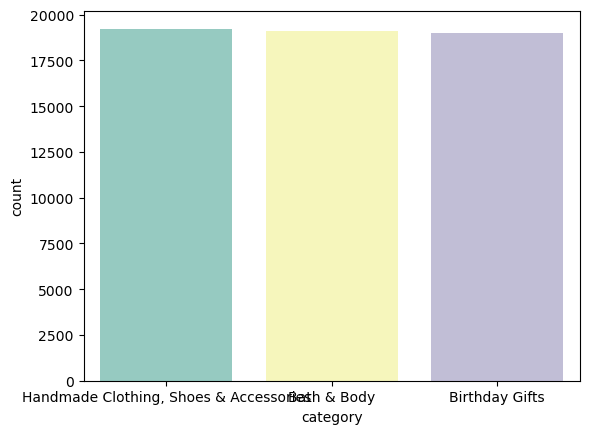

In [210]:
#2
#Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
#For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?
ax=sns.barplot(data=frequency_table, y=frequency_table['count'][2:5], x=frequency_table['category'][2:5]
               ,palette="Set3", hue=frequency_table['category'][2:5], legend=False) 


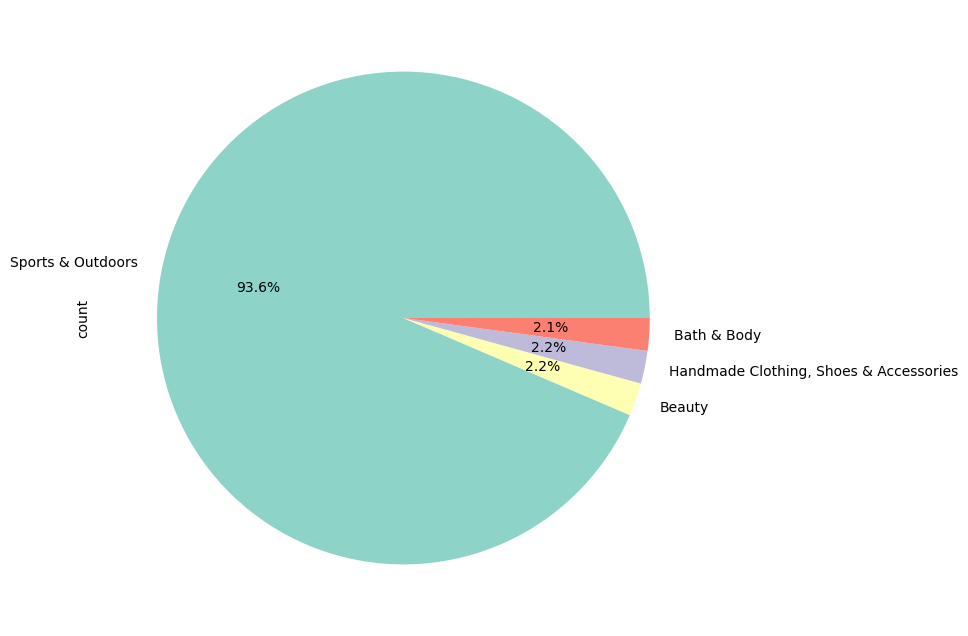

In [269]:
preferred_columns = frequency_table.iloc[0:4]
preferred_columns.set_index('category', inplace=True)
preferred_columns['count'].plot.pie(
    autopct='%1.1f%%',        # Display percentages on pie slices
    colors=sns.color_palette("Set3"),  # Use Seaborn's color palette
    figsize=(8, 8)            # Adjust the figure size
);

In [353]:
#Part2
display(df['price'].agg(['mean', 'median']))
display(df['price'].mode()[0])
#there's significant difference between the avg price ($89.24) and the most common price ($9.99), this might be due to products that
#have much higher prices than the mean, pulling the average price up. 



mean      89.243809
median    19.090000
Name: price, dtype: float64

9.99

In [317]:
d_stats = df[['price']].describe().round(2)
d_stats

,price
count,2443651.00
mean,89.24
std,345.61
min,0.00
25%,9.99
50%,19.09
75%,45.99
max,100000.00


In [347]:
print(f'the variance of the price is: {round(df['price'].var(), 2)}')

the variance of the price is: 119445.49


In [327]:
range = df['price'].max() - df['price'].min()
range

100000.0

In [341]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
print(f'the IQR is: {IQR}')

the IQR is: 36.0


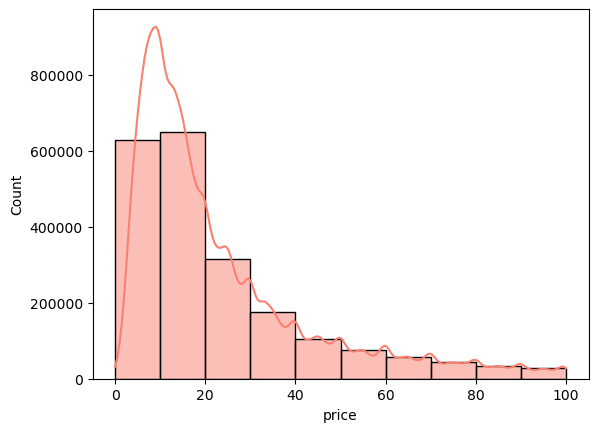

In [384]:
sns.histplot(df['price'][df['price'] < 100], kde=True, bins= 10, color='salmon');


the graph is hard to read due to the outliers present in the price data. If we filter the price column to only graphically represent the prices under 
100 dollars, the graph gets a more natural shape and it becomes easier to read. Given that 75% of the products cost less than $50 (according to the 
 75% quartile, this filtering is appropiate to see the distribution of prices. 
In this graph, it is easy to see that the majority of products fall within the 10-20 dollar range. 

<Axes: xlabel='price'>

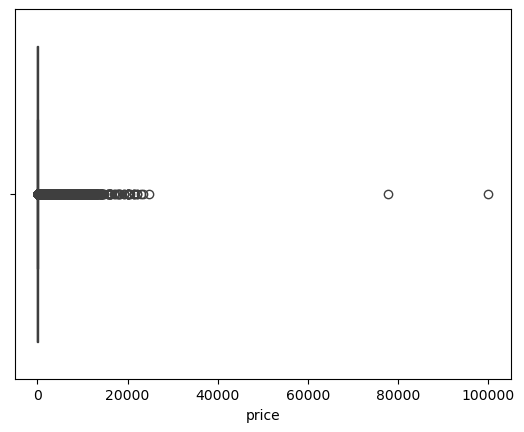

In [396]:
sns.boxplot(x=df['price']) #from this first representation on a boxplot, we can see there are two outliers very far away from 
#the majority of values, which is pulling the average price upwards and distorting our data. 

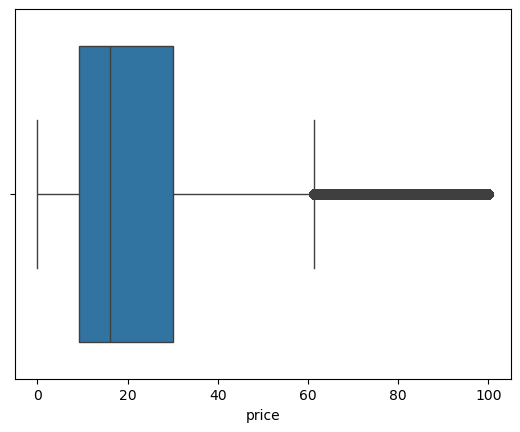

In [400]:
sns.boxplot(x= df['price'][df['price'] < 100]);

in this secod representation, after filtering out to only represent the prices under $100, we see a more meaningul graph,
and we can observe that the majority of prices fall within a range of approximately 36 units, which is the IQR calculated
earlier. 

In [407]:
#Part3


,mean,std,min,max
category,,,,
3D Printers,260.06,1223.95,0,14767
3D Printing & Scanning,31.80,582.19,0,23109
Abrasive & Finishing Products,428.86,1371.32,0,16051
Action Cameras,175.35,1262.39,0,29686
Adapters,6904.05,21581.61,0,143355
...,...,...,...,...
Wind Instruments,332.98,1634.98,0,19309
Window Treatments,2274.03,6638.05,0,53918
Women,1248.12,5530.77,0,479359


In [416]:
display(df['stars'].agg(['mean', 'median']))
display(df['stars'].mode()[0])

mean      2.152836
median    0.000000
Name: stars, dtype: float64

0.0

In [418]:
df.groupby('category')['stars'].describe() 

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
3D Printers,248.0,2.643145,2.044909,0.0,0.0,3.9,4.4,5.0
3D Printing & Scanning,4067.0,0.148267,0.782050,0.0,0.0,0.0,0.0,5.0
Abrasive & Finishing Products,250.0,4.125200,1.145466,0.0,4.2,4.5,4.6,5.0
Action Cameras,1697.0,1.281615,1.865208,0.0,0.0,0.0,3.4,5.0
Adapters,254.0,4.142520,0.956486,0.0,4.1,4.4,4.5,5.0
...,...,...,...,...,...,...,...,...
Wind Instruments,250.0,2.026400,2.129809,0.0,0.0,0.0,4.2,5.0
Window Treatments,239.0,4.107950,1.078465,0.0,4.2,4.4,4.6,5.0
Women,17772.0,4.169446,0.656877,0.0,4.1,4.3,4.5,5.0


From the table above we can see ratings follow a similar trend across categories. There isn't any category which follows a specific trend.
However, we could say that ratings are only provided if the rating is high, as there are many categories with the 50% quantile being 0, which means 50% of the reviews is 0, which I believe could also mean 'not rated'.

In [427]:
df['stars'].var()

4.81743402976196

In [431]:
Q1 = df['stars'].quantile(0.25)
Q3 = df['stars'].quantile(0.75)
IQR = Q3 - Q1
IQR

4.4

From the stats above, we can see that the variance is significantly high, which means ratings can be very different, and differ from the mean significantly. Also, the IQR tells us that 50% of ratings fall within a 4.4 star range. Considering ratings go from 0 to 5, this is a very large range and means there are ratings all across the rating scheme. 

In [440]:
display(df['stars'].skew())
display(df['stars'].kurtosis())

0.08120735761080985

-1.9260061280432985

The skewness, calculated above, is very low, which implies there are no significant tails in the data. The negative kurtosis means that the data has ligher tails than normally distributed, which implies values are closer to the mean. Considering the mean is only two units away from the mode, this analysis makes sense.

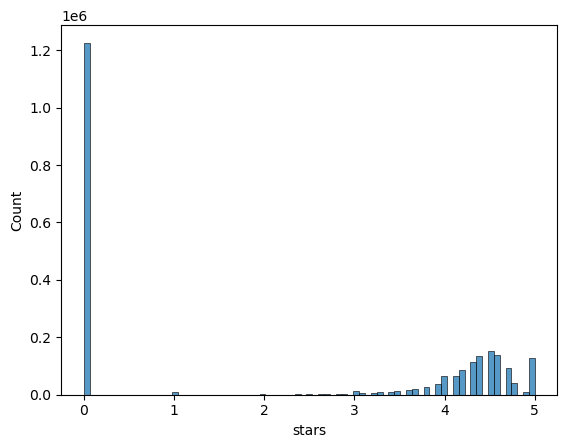

In [449]:
sns.histplot(x=df['stars']);

From the graph above we can clearly see the most common rating (the mode) is 0 stars. We can also see the majority of ratings
fall under the 4-5 star range. 

Summary Report

- We have identified the top 5 categories: Sports & Outdoors, Beauty, Handmade Clothing, Bath & Body, and Birthday gifts
- We found out that Sports & Outdoors is the category with the majority of products, with an overwhelmingly 93.6%
- We found that the mean price is almost $90. However, this average is being pulled upwards by a few outliers distorting our data.
- In fact, the majority of prices fall between 10 and 20 dollars, $9.99 being the most common price.
- In terms of ratings, we have determined that the most common rating is 0 stars, which can also mean the majority of products have not been rated.
- Additonally, we have seen that the average rating is approximately 2.5 stars. However, this mean is also being inlfuenced by the number of ratings that have 0 stars. 
- Aside from the 0-star ratings, most ratings fall within the 4-5 star range. 

<Axes: xlabel='stars', ylabel='Count'>

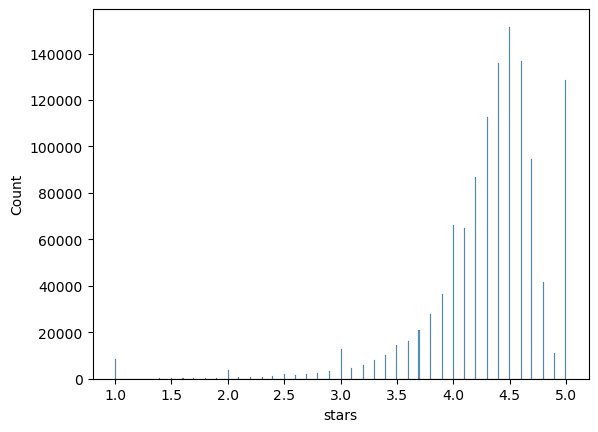

In [455]:
sns.histplot(x=df['stars'][df['stars'] > 0]);